In [1]:
from pathlib import Path

sam40_path = Path("../../datasets/SAM40/artifact_removal")

mat_files = list(sam40_path.glob("*.mat"))

print(f"Total files: {len(mat_files)}")

for f in mat_files[:10]:
    print(f.name)

Total files: 2
Cleaned_EEG.mat
Corrupted_EEG.mat


In [2]:
from scipy.io import loadmat

data = loadmat("../../datasets/SAM40/artifact_removal/Cleaned_EEG.mat")

print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'Clean_data'])


In [3]:
for key, value in data.items():
    if not key.startswith("__"):
        print(f"{key}:")
        print(f"Type: {type(value)}")
        try:
            print(f"Shape: {value.shape}")
        except:
            pass
        print()

Clean_data:
Type: <class 'numpy.ndarray'>
Shape: (32, 3200)



In [4]:
clean_data = data["Clean_data"]

print(type(clean_data))
print(clean_data.shape)

<class 'numpy.ndarray'>
(32, 3200)


In [5]:
from scipy.io import loadmat

corrupted = loadmat("../../datasets/SAM40/artifact_removal/Corrupted_EEG.mat")

print(corrupted.keys())

dict_keys(['__header__', '__version__', '__globals__', 'Data'])


In [6]:
for key, value in corrupted.items():
    if not key.startswith("__"):
        print(key)
        print(type(value))
        print(value.shape)

Data
<class 'numpy.ndarray'>
(32, 3200)


In [7]:
from pathlib import Path

for folder in [
    "../../datasets/SAM40/raw_data",
    "../../datasets/SAM40/filtered_data",
    "../../datasets/SAM40/artifact_removal"
]:
    files = list(Path(folder).glob("*.mat"))
    print(folder)
    print("Count:", len(files))
    print([f.name for f in files[:5]])
    print()

../../datasets/SAM40/raw_data
Count: 480
['Arithmetic_sub_10_trial1.mat', 'Arithmetic_sub_10_trial2.mat', 'Arithmetic_sub_10_trial3.mat', 'Arithmetic_sub_11_trial1.mat', 'Arithmetic_sub_11_trial2.mat']

../../datasets/SAM40/filtered_data
Count: 480
['Arithmetic_sub_10_trial1.mat', 'Arithmetic_sub_10_trial2.mat', 'Arithmetic_sub_10_trial3.mat', 'Arithmetic_sub_11_trial1.mat', 'Arithmetic_sub_11_trial2.mat']

../../datasets/SAM40/artifact_removal
Count: 2
['Cleaned_EEG.mat', 'Corrupted_EEG.mat']



In [8]:
from scipy.io import loadmat

sample = loadmat(
    "../../datasets/SAM40/filtered_data/Arithmetic_sub_10_trial1.mat"
)

print(sample.keys())

dict_keys(['__header__', '__version__', '__globals__', 'Clean_data'])


In [9]:
clean_data = sample["Clean_data"]

print(type(clean_data))
print(clean_data.shape)
print(clean_data.dtype)

<class 'numpy.ndarray'>
(32, 3200)
float64


In [10]:
print(clean_data[:5, :5])

[[-6.32767516 -2.75769617  3.13744687 -0.10277298  1.54944558]
 [-9.72795516  0.79250038  6.03029432  2.23108839  5.47488412]
 [-7.96639039  0.19473651  0.7919495   3.4647126  10.46369015]
 [-5.88997022 -2.37208058  0.29275504  6.34011885  9.82544376]
 [-4.54440519 -2.97580998  0.3124827   4.03410696  7.04047008]]


In [11]:
import numpy as np

print("Min:", np.min(clean_data))
print("Max:", np.max(clean_data))
print("Mean:", np.mean(clean_data))
print("Std:", np.std(clean_data))

Min: -29.956907132143854
Max: 41.114404492375684
Mean: -0.038034572177730555
Std: 5.611022465052506


In [12]:
from pathlib import Path

files = list(Path("../../datasets/SAM40/filtered_data").glob("*.mat"))

subjects = set()
tasks = set()

for f in files:
    parts = f.stem.split("_")

    subjects.add(parts[2])  # sub number
    tasks.add(parts[0])     # Arithmetic, etc.

print("Total files:", len(files))
print("Subjects:", len(subjects))
print(sorted(list(subjects))[:10])

print("\nTasks:")
print(sorted(tasks))

Total files: 480
Subjects: 41
['1', '10', '11', '12', '13', '14', '15', '16', '17', '18']

Tasks:
['Arithmetic', 'Mirror', 'Relax', 'Stroop']


In [13]:
import pandas as pd

xls = pd.ExcelFile("../../datasets/SAM40/scales.xls")

print(xls.sheet_names)

['scales']


In [14]:
import pandas as pd

df = pd.read_excel("../../datasets/SAM40/scales.xls")

print(df.shape)
df.head()

(41, 10)


,Subject No.,Trial_1,Unnamed: 2,Unnamed: 3,Trial_2,Unnamed: 5,Unnamed: 6,Trial_3,Unnamed: 8,Unnamed: 9
0,NaN,Maths,Symmetry,Stroop,Maths,Symmetry,Stroop,Maths,Symmetry,Stroop
1,1.0,6,3,3,7,5,2,4,7,4
2,2.0,3,4,5,3,4,4,7,5,3
3,3.0,5,3,4,3,5,5,8,7,5
4,4.0,5,3,4,3,5,2,7,5,5


In [15]:
print(df.columns.tolist())

['Subject No.', 'Trial_1', 'Unnamed: 2', 'Unnamed: 3', 'Trial_2', 'Unnamed: 5', 'Unnamed: 6', 'Trial_3', 'Unnamed: 8', 'Unnamed: 9']


In [16]:
import pandas as pd

df = pd.read_excel(
    "../../datasets/SAM40/scales.xls",
    header=None
)

df

,0,1,2,3,4,5,6,7,8,9
0,Subject No.,Trial_1,NaN,NaN,Trial_2,NaN,NaN,Trial_3,NaN,NaN
1,NaN,Maths,Symmetry,Stroop,Maths,Symmetry,Stroop,Maths,Symmetry,Stroop
2,1,6,3,3,7,5,2,4,7,4
3,2,3,4,5,3,4,4,7,5,3
4,3,5,3,4,3,5,5,8,7,5
5,4,5,3,4,3,5,2,7,5,5
6,5,6,6,6,5,3,2,5,7,3
7,6,5,4,2,4,3,3,8,6,5
8,7,5,5,4,3,3,3,6,3,6
9,8,3,5,4,6,6,3,5,6,3


In [17]:
print(df)

              0        1         2       3        4         5       6  \
0   Subject No.  Trial_1       NaN     NaN  Trial_2       NaN     NaN   
1           NaN    Maths  Symmetry  Stroop    Maths  Symmetry  Stroop   
2             1        6         3       3        7         5       2   
3             2        3         4       5        3         4       4   
4             3        5         3       4        3         5       5   
5             4        5         3       4        3         5       2   
6             5        6         6       6        5         3       2   
7             6        5         4       2        4         3       3   
8             7        5         5       4        3         3       3   
9             8        3         5       4        6         6       3   
10            9        3         6       4        4         4       4   
11           10        3         4       4        4         5       3   
12           11        7         3       4        6

In [18]:
from pathlib import Path

files = sorted(
    Path("../../datasets/SAM40/filtered_data").glob("*.mat")
)

for f in files[:20]:
    print(f.name)

Arithmetic_sub_10_trial1.mat
Arithmetic_sub_10_trial2.mat
Arithmetic_sub_10_trial3.mat
Arithmetic_sub_11_trial1.mat
Arithmetic_sub_11_trial2.mat
Arithmetic_sub_11_trial3.mat
Arithmetic_sub_12_trial1.mat
Arithmetic_sub_12_trial2.mat
Arithmetic_sub_12_trial3.mat
Arithmetic_sub_13_trial1.mat
Arithmetic_sub_13_trial2.mat
Arithmetic_sub_13_trial3.mat
Arithmetic_sub_14_trial1.mat
Arithmetic_sub_14_trial2.mat
Arithmetic_sub_14_trial3.mat
Arithmetic_sub_15_trial1.mat
Arithmetic_sub_15_trial2.mat
Arithmetic_sub_15_trial3.mat
Arithmetic_sub_16_trial1.mat
Arithmetic_sub_16_trial2.mat


In [19]:
print(df.iloc[:10, :])

             0        1         2       3        4         5       6        7  \
0  Subject No.  Trial_1       NaN     NaN  Trial_2       NaN     NaN  Trial_3   
1          NaN    Maths  Symmetry  Stroop    Maths  Symmetry  Stroop    Maths   
2            1        6         3       3        7         5       2        4   
3            2        3         4       5        3         4       4        7   
4            3        5         3       4        3         5       5        8   
5            4        5         3       4        3         5       2        7   
6            5        6         6       6        5         3       2        5   
7            6        5         4       2        4         3       3        8   
8            7        5         5       4        3         3       3        6   
9            8        3         5       4        6         6       3        5   

          8       9  
0       NaN     NaN  
1  Symmetry  Stroop  
2         7       4  
3         5       3 

In [20]:
print(df.iloc[-5:, :])

     0  1  2  3  4  5  6  7  8  9
37  36  4  4  6  5  4  3  5  5  5
38  37  6  5  4  5  3  2  8  4  6
39  38  6  4  5  5  6  3  4  5  3
40  39  6  4  3  5  5  3  6  3  5
41  40  3  5  5  4  6  5  4  4  3


In [21]:
from pathlib import Path
from scipy.io import loadmat

shapes = set()

for file in Path("../../datasets/SAM40/filtered_data").glob("*.mat"):
    eeg = loadmat(file)["Clean_data"]
    shapes.add(eeg.shape)

print(shapes)

{(32, 3200)}


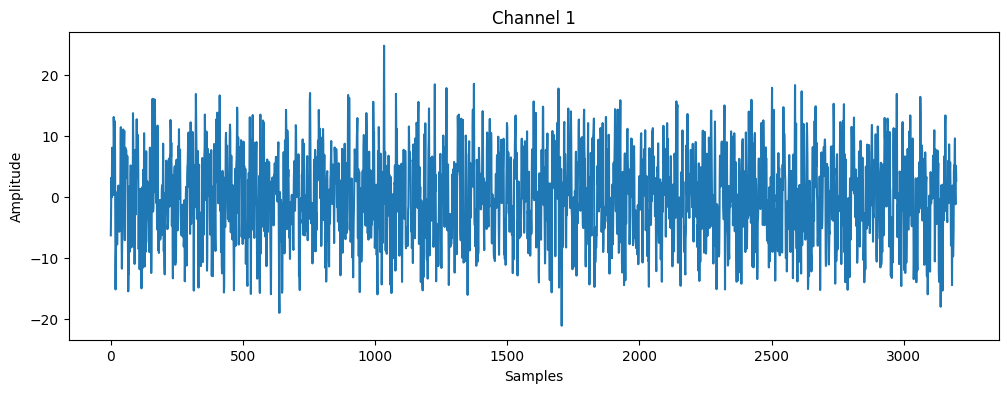

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))
plt.plot(clean_data[0])
plt.title("Channel 1")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.show()

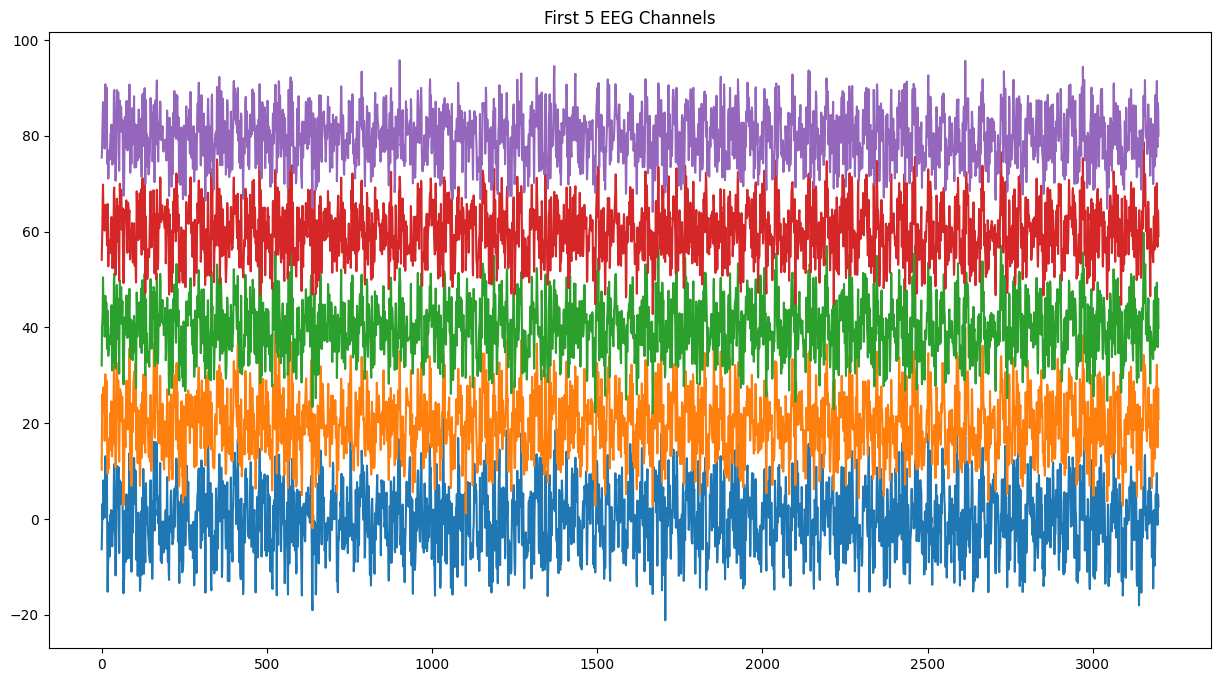

In [23]:
plt.figure(figsize=(15,8))

for i in range(5):
    plt.plot(clean_data[i] + i*20)

plt.title("First 5 EEG Channels")
plt.show()

In [24]:
with open("../../datasets/SAM40/Coordinates.locs", "r") as f:
    for _ in range(10):
        print(f.readline().strip())

1	       0	0.00055556	      Cz
2	       0	   0.275	      Fz
3	     -18	 0.53644	     Fp1
4	     -54	 0.53628	      F7
5	     -39	 0.35611	      F3
6	   -44.9	 0.19222	     FC1
7	   -89.9	 0.27444	      C3
8	     -69	 0.41889	     FC5
9	     -72	 0.66111	     FT9
10	     -90	   0.536	      T7


In [25]:
with open("../../datasets/SAM40/Coordinates.locs", "r") as f:
    lines = f.readlines()

print("Total channels:", len(lines))

for line in lines:
    print(line.strip().split()[-1])

Total channels: 32
Cz
Fz
Fp1
F7
F3
FC1
C3
FC5
FT9
T7
CP5
CP1
P3
P7
PO9
O1
Pz
Oz
O2
PO10
P8
P4
CP2
CP6
T8
FT10
FC6
C4
FC2
F4
F8
Fp2


In [26]:
import pandas as pd

df = pd.read_excel(
    "../../datasets/SAM40/scales.xls",
    header=None
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

print(df)

              0        1         2       3        4         5       6  \
0   Subject No.  Trial_1       NaN     NaN  Trial_2       NaN     NaN   
1           NaN    Maths  Symmetry  Stroop    Maths  Symmetry  Stroop   
2             1        6         3       3        7         5       2   
3             2        3         4       5        3         4       4   
4             3        5         3       4        3         5       5   
5             4        5         3       4        3         5       2   
6             5        6         6       6        5         3       2   
7             6        5         4       2        4         3       3   
8             7        5         5       4        3         3       3   
9             8        3         5       4        6         6       3   
10            9        3         6       4        4         4       4   
11           10        3         4       4        4         5       3   
12           11        7         3       4        6

In [27]:
print(df.shape)

print(df.tail())

(42, 10)
     0  1  2  3  4  5  6  7  8  9
37  36  4  4  6  5  4  3  5  5  5
38  37  6  5  4  5  3  2  8  4  6
39  38  6  4  5  5  6  3  4  5  3
40  39  6  4  3  5  5  3  6  3  5
41  40  3  5  5  4  6  5  4  4  3
